# EDA

## 1. Import des données

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from main import load_dataset

In [6]:
titanic_df = load_dataset()

titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Exploration élementaire des données

### 2.1 Contexte et dictionnaire de données

|Variable|Définition|Key|
|--|--|--|
|PassengerId|ID du passager||
|Survived|Le passager a-t'il survécu ?|`0` = non et `1` = oui|
|Pclass|La classe de voyage du passager|`1` = 1ère classe, `2` = 2nd classe, `3` = 3ème classe|
|Sex|Le sexe du passager||
|Age|L'âge du passager en années||
|Sibsp|Nombre de passager faisant partie de la fraterie ou qui sont l'époux du passager à bords||
|Parch|Nombre de passager étant des parents ou enfants du passager à bords||
|Ticket|ID du ticket du passager||
|Fare|Tarif que s'est acquitté le passager||
|Cabin|Numéro de cabine du passager||
|Embarked|Code du port d'embarquement du passager|`C` = Cherbourg, `Q` = Queenstown, `S` = Southampton|

### 2.2 Qualité des données

Description élémentaire du dataset.

In [7]:
titanic_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [10]:
titanic_df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


> Le jeu de donnée est lacunaire, 177 âges ne sont pas spécifiés, 687 cabines non renseignées et 2 port d'origine sont manquants.

In [13]:
missing = pd.DataFrame({
    "n_missing": titanic_df.isna().sum(),
    "pct_missing": (titanic_df.isna().mean() * 100).round(1),
}).query("n_missing > 0").sort_values("pct_missing", ascending = False)
display(missing)

print("Duplicated rows:", titanic_df.duplicated().sum())
print("Duplicated tickets:", titanic_df.Ticket.duplicated().sum())
print("Duplicated PassengerId:", titanic_df.PassengerId.duplicated().sum())

,n_missing,pct_missing
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


Duplicated rows: 0
Duplicated tickets: 210
Duplicated PassengerId: 0


> **Observations**
> - `Cabin` est manquante à **77 %** : trop incomplète pour être imputée, mais le fait d'être renseignée est informatif.
> - `Age` est manquante à **20 %**.
> - `Embarked` n'a que **2 valeurs manquantes** : imputation par le mode sans risque.
> - Aucun doublon de ligne, en revanche **210 billets sont partagés** (groupes / familles).

In [14]:
print(titanic_df.groupby("Pclass").Age.apply(lambda s: s.isna().mean()).round(3).rename("pct_age_missing"))
print("\n")
print(titanic_df.groupby(titanic_df.Age.isna()).Survived.mean().round(3).rename("survival_rate").rename_axis("age_missing"))

Pclass
1    0.139
2    0.060
3    0.277
Name: pct_age_missing, dtype: float64


age_missing
False    0.406
True     0.294
Name: survival_rate, dtype: float64


> L'âge manque surtout en **3ᵉ classe** (28 % contre 14 % en 1ʳᵉ et 6 % en 2ᵉ) : l'absence n'est donc pas aléatoire. On imputera l'âge **par groupe** plutôt qu'avec une médiane globale.

### 2.3 Analyse univariée

#### 2.3.1 Variable cible

Survived
0    549
1    342
Name: count, dtype: int64 

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


/var/folders/84/gf2d3j6j7w90bhvxcsl9t0wr0000gn/T/ipykernel_23647/2416375071.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Died (0)", "Survived (1)"])


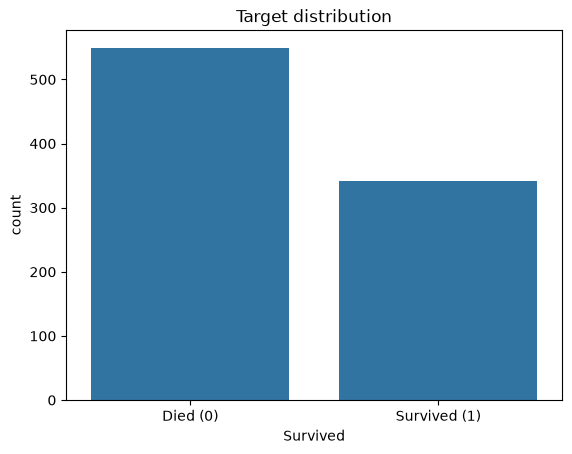

In [15]:
print(titanic_df.Survived.value_counts(), "\n")
print(titanic_df.Survived.value_counts(normalize=True).round(3))

ax = sns.countplot(data=titanic_df, x="Survived")
ax.set_xticklabels(["Died (0)", "Survived (1)"])
ax.set_title("Target distribution")
plt.show()

> Le taux de survie global est de **38,4 %** : classes modérément déséquilibrées (61,6 % / 38,4 %), sans nécessité de rééquilibrage.

#### 2.3.2 Variables numériques

In [17]:
cols = ["Age", "SibSp", "Parch", "Fare"]
display(titanic_df[num_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2))

print("\nSkewness:")
print(titanic_df[cols].skew().round(2))

,Age,SibSp,Parch,Fare
count,714.00,891.00,891.00,891.00
mean,29.70,0.52,0.38,32.20
std,14.53,1.10,0.81,49.69
min,0.42,0.00,0.00,0.00
1%,1.00,0.00,0.00,0.00
5%,4.00,0.00,0.00,7.22
25%,20.12,0.00,0.00,7.91
50%,28.00,0.00,0.00,14.45
75%,38.00,1.00,0.00,31.00
95%,56.00,3.00,2.00,112.08



Skewness:
Age      0.39
SibSp    3.70
Parch    2.75
Fare     4.79
dtype: float64


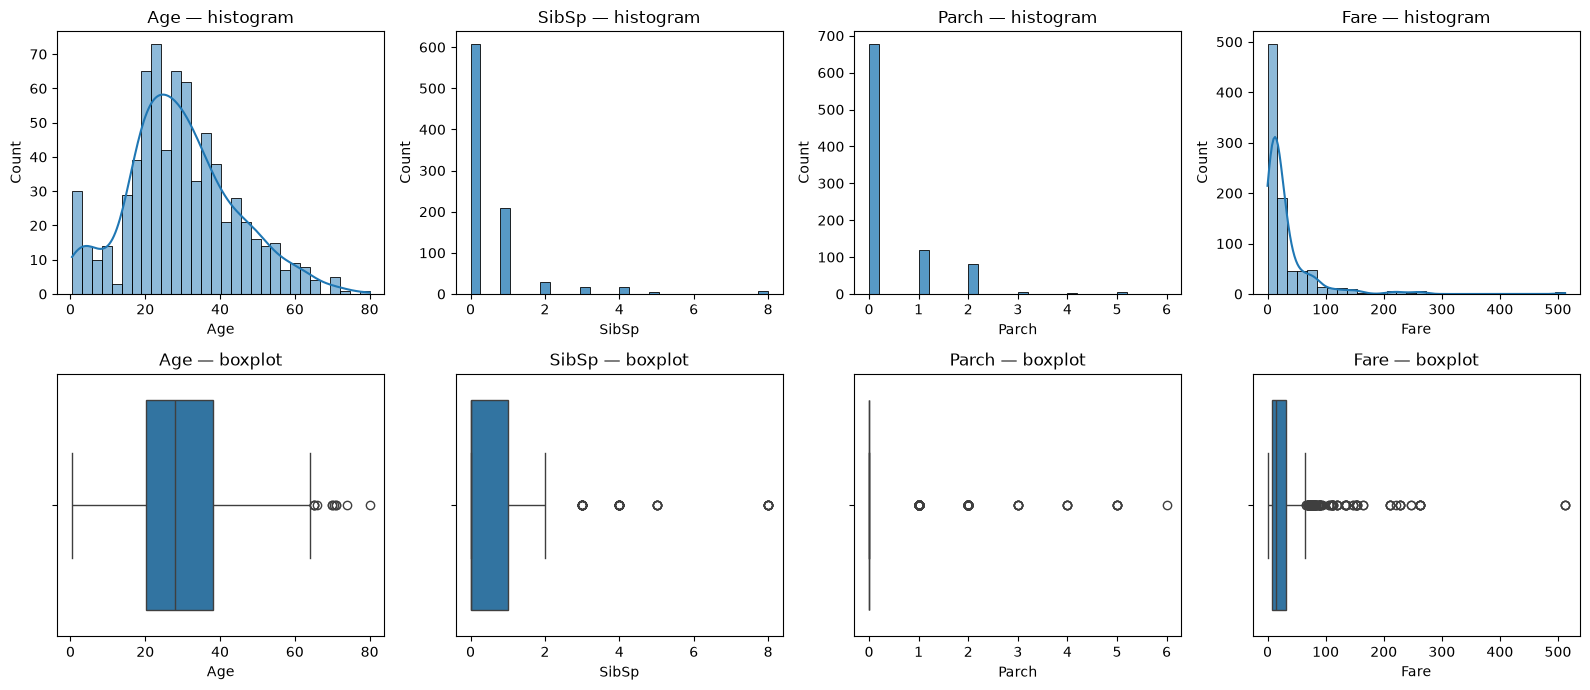

In [36]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for i, c in enumerate(num_cols):
    sns.histplot(titanic_df[c].dropna(), kde=(c in ["Age", "Fare"]), bins=30, ax=axes[0, i])
    axes[0, i].set_title(f"{c} — histogram")
    sns.boxplot(x=titanic_df[c], ax=axes[1, i])
    axes[1, i].set_title(f"{c} — boxplot")
    
plt.tight_layout()
plt.show()

> - `Age` : distribution proche de la normale (asymétrie 0,39), médiane 28 ans, quelques enfants en bas âge (min 0,42).
> - `Fare` : très asymétrique à droite (asymétrie 4,8), médiane 14,45 contre moyenne 32,2 ; max à 512.
> - `SibSp` / `Parch` : fortement concentrées sur 0 (la majorité voyage seule).

#### 2.3.3 Variables catégorielles

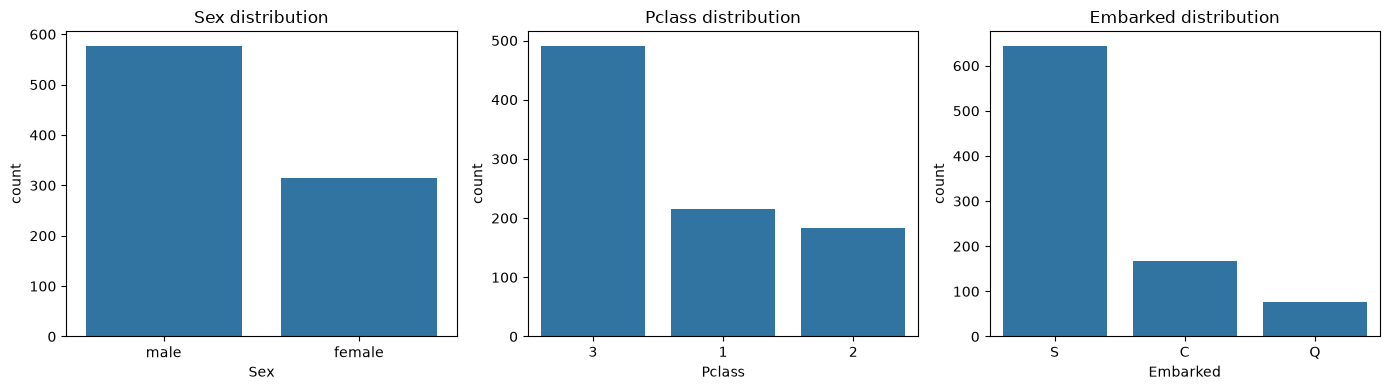

Sex
male      0.648
female    0.352
Name: proportion, dtype: float64 

Pclass
3    0.551
1    0.242
2    0.207
Name: proportion, dtype: float64 

Embarked
S      0.723
C      0.189
Q      0.086
NaN    0.002
Name: proportion, dtype: float64 



In [37]:
cat_cols = ["Sex", "Pclass", "Embarked"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, c in zip(axes, cat_cols):
    sns.countplot(data = titanic_df, x = c, ax = ax, order = titanic_df[c].value_counts().index)
    ax.set_title(f"{c} distribution")
    
plt.tight_layout()
plt.show()

for c in cat_cols:
    print(titanic_df[c].value_counts(normalize=True, dropna=False).round(3), "\n")

> Le navire transportait majoritairement des **hommes (65 %)**, des passagers de **3ᵉ classe (55 %)** et embarqués à **Southampton (72 %)**.

## 3. Analyse bivariée : relation à la survie

### 3.1 Varibales catégorielles

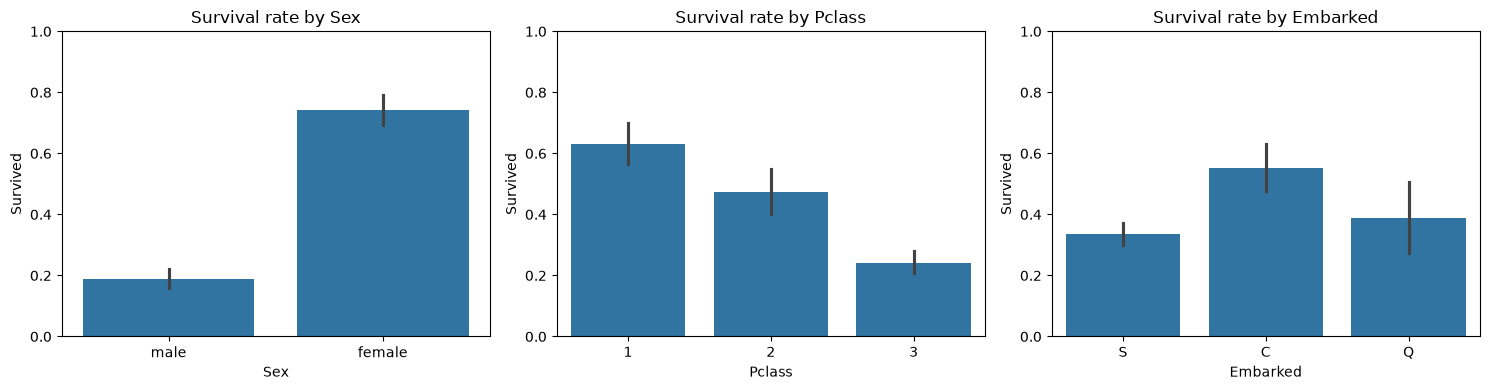

,n,survival_rate
Sex,,
female,314,0.742
male,577,0.189


,n,survival_rate
Pclass,,
1,216,0.630
2,184,0.473
3,491,0.242


,n,survival_rate
Embarked,,
C,168,0.554
Q,77,0.390
S,644,0.337
NaN,2,1.000


In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, c in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(data = titanic_df, x = c, y = "Survived", ax = ax, errorbar = ("ci", 95))
    ax.set_title(f"Survival rate by {c}")
    ax.set_ylim(0, 1)
    
plt.tight_layout()
plt.show()

for c in ["Sex", "Pclass", "Embarked"]:
    display(titanic_df.groupby(c, dropna=False).Survived.agg(n="count", survival_rate="mean").round(3))

> - **Sexe** : 74 % des femmes ont survécu contre 19 % des hommes, c'est le facteur le plus discriminant.
> - **Classe** : 63 % en 1ère, 47 % en 2nd, 24 % en 3ème.
> - **Port** : Cherbourg (55 %) > Queenstown (39 %) > Southampton (34 %).

In [40]:
print(pd.crosstab(titanic_df.Embarked, titanic_df.Pclass, normalize="index").round(3))

Pclass        1      2      3
Embarked                     
C         0.506  0.101  0.393
Q         0.026  0.039  0.935
S         0.197  0.255  0.548


### 3.2 Variables numériques

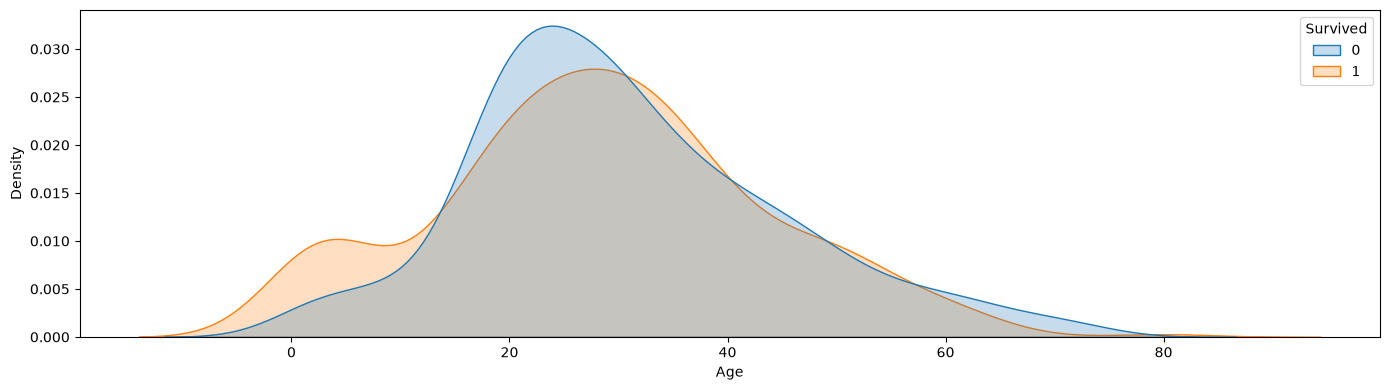

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(14, 4))

sns.kdeplot(data=titanic_df, x="Age", hue="Survived", fill=True, common_norm=False, ax=ax)
axes[0].set_title("Age distribution by survival")

plt.tight_layout()
plt.show()

In [22]:
titanic_df["AgeBin"] = pd.cut(titanic_df.Age, [0, 12, 18, 35, 60, 80])
titanic_df["FareQuartile"] = pd.qcut(titanic_df.Fare, 4)

display(titanic_df.groupby("AgeBin", observed=True).Survived.agg(n="count", survival_rate="mean").round(3))
display(titanic_df.groupby("FareQuartile", observed=True).Survived.agg(n="count", survival_rate="mean").round(3))

,n,survival_rate
AgeBin,,
"(0, 12]",69,0.580
"(12, 18]",70,0.429
"(18, 35]",358,0.383
"(35, 60]",195,0.400
"(60, 80]",22,0.227


,n,survival_rate
FareQuartile,,
"(-0.001, 7.91]",223,0.197
"(7.91, 14.454]",224,0.304
"(14.454, 31.0]",222,0.455
"(31.0, 512.329]",222,0.581


> - **Âge** : les enfants de moins de 12 ans survivent nettement mieux (58 %), les plus de 60 ans nettement moins (23 %). Entre les deux, l'effet est faible.
> - **Fare** : Plus le montant payé par le passager était élevé, plus ses chance de survie l'était également.

### 3.3 La variable de la famille

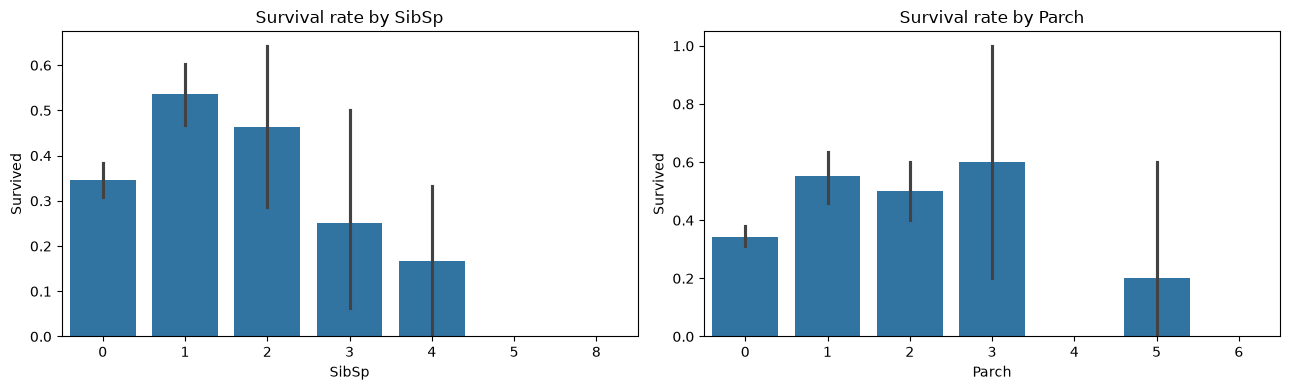

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.barplot(data = titanic_df, x="SibSp", y="Survived", ax=axes[0]); axes[0].set_title("Survival rate by SibSp")
sns.barplot(data = titanic_df, x="Parch", y="Survived", ax=axes[1]); axes[1].set_title("Survival rate by Parch")

plt.tight_layout()
plt.show()

> Voyager avec 1 à 3 proches améliore les chances de survie, voyager seul ou avec une très grande famille (SibSp ≥ 3) les réduit. Les effectifs des grandes familles sont très faibles (à interpréter avec prudence).

## 4. Analyse multivariée

Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


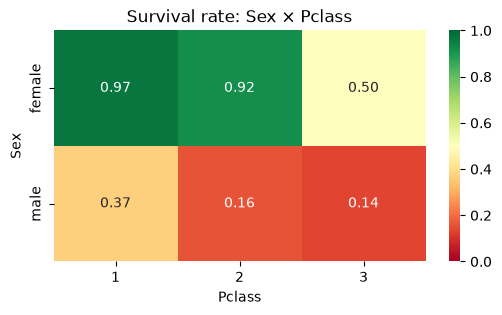

In [45]:
pivot = titanic_df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean")
display(pivot.round(3))

plt.figure(figsize=(6, 3))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Survival rate: Sex × Pclass")
plt.show()

> **Interaction forte :** presque toutes les femmes de 1ère et 2nd classe ont survécu (92 – 97 %), alors que celles de 3ème classe n'atteignent que 50 %. Chez les hommes, seule la 1ère classe dépasse nettement 15 % (37 %).

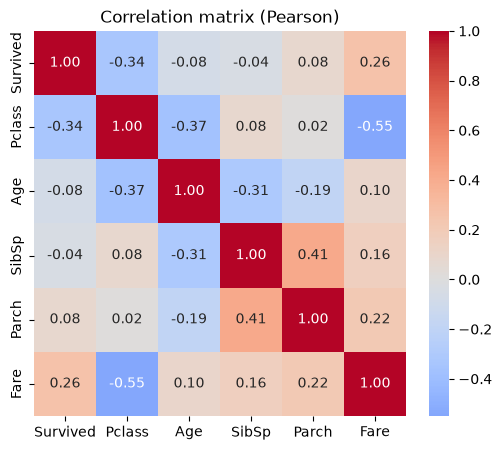

In [46]:
corr = titanic_df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr()

plt.figure(figsize=(6, 5))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (Pearson)")

plt.show()

> `Survived` est corrélée à `Pclass` (−0,34) et `Fare` (+0,26). `Pclass` et `Fare` sont elles-mêmes fortement corrélées entre elles (information redondante). L'âge n'est que faiblement corrélé linéairement (−0,08), mais son effet est non linéaire (enfants).

## 5. Ingénierie de donnée

### 5.1 Feature engineering

In [59]:
titanic_df["Title"] = titanic_df.Name.str.extract(r",\s*([^\.]+)\.")
titanic_df["Title"] = titanic_df.Title.replace({
    "Mlle": "Miss", 
    "Ms": "Miss", 
    "Mme": "Mrs"
})
counts = titanic_df.Title.value_counts()
titanic_df["Title"] = titanic_df.Title.where(titanic_df.Title.isin(counts[counts >= 10].index), "Other")

titanic_df.Title.value_counts()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Other      23
Name: count, dtype: int64

In [64]:
# Create a new variable FamilySize that corresponds to the estimated family size onboard witht the passenger
titanic_df["FamilySize"] = titanic_df.SibSp + titanic_df.Parch + 1

# Create a new variable isAlone
titanic_df["IsAlone"] = (titanic_df.FamilySize == 1).astype(int)

titanic_df["HasCabin"] = titanic_df.Cabin.notna().astype(int)

titanic_df["Deck"] = titanic_df.Cabin.str[0]

In [65]:
display(titanic_df.groupby("Title").agg(n=("Survived", "size"), survival_rate=("Survived", "mean"),
                                median_age=("Age", "median")).round(2))
display(titanic_df.groupby("FamilySize").Survived.agg(n="count", survival_rate="mean").round(3))
display(titanic_df.groupby("HasCabin").Survived.agg(n="count", survival_rate="mean").round(3))
display(titanic_df.groupby("Deck").Survived.agg(n="count", survival_rate="mean").round(2))

,n,survival_rate,median_age
Title,,,
Master,40,0.57,3.5
Miss,185,0.70,21.0
Mr,517,0.16,30.0
Mrs,126,0.79,35.0
Other,23,0.35,48.5


,n,survival_rate
FamilySize,,
1,537,0.304
2,161,0.553
3,102,0.578
4,29,0.724
5,15,0.200
6,22,0.136
7,12,0.333
8,6,0.000
11,7,0.000


,n,survival_rate
HasCabin,,
0,687,0.300
1,204,0.667


,n,survival_rate
Deck,,
A,15,0.47
B,47,0.74
C,59,0.59
D,33,0.76
E,32,0.75
F,13,0.62
G,4,0.50
T,1,0.00


> - **`Title`** résume sexe, âge et statut marital : `Mr` 16 %, `Miss` 70 %, `Mrs` 79 %, `Master` 57 %.
> - **`FamilySize`** : pic de survie à 2 – 4 personnes, effondrement à partir de 5.
> - **`HasCabin`** : 67 % de survie quand la cabine est connue contre 30 % sinon (probablement un marqueur de richesse/classe), et un effet de la façon dont les données ont été collectées (les cabines des survivants ont été plus souvent renseignées).
> - **`Deck`** : effectifs trop faibles pour des conclusions fiables.

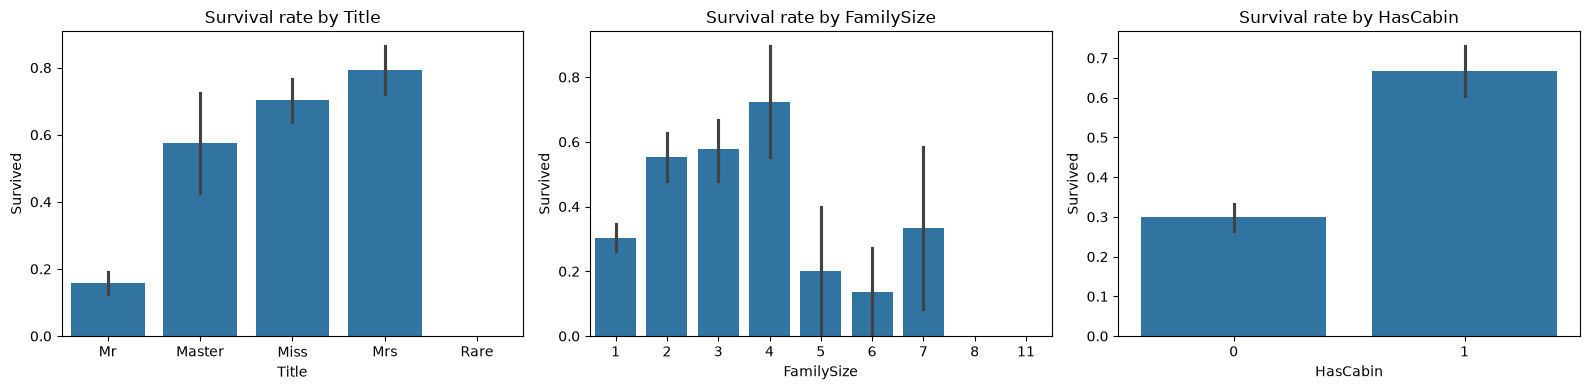

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=titanic_df, x="Title", y="Survived", ax=axes[0], order=["Mr", "Master", "Miss", "Mrs", "Rare"])
sns.barplot(data=titanic_df, x="FamilySize", y="Survived", ax=axes[1])
sns.barplot(data=titanic_df, x="HasCabin", y="Survived", ax=axes[2])

for ax, t in zip(axes, ["Title", "FamilySize", "HasCabin"]):
    ax.set_title(f"Survival rate by {t}")
    
plt.tight_layout()
plt.show()

### 5.2 Imputation des valeurs manquantes

In [69]:
# Sets the median age for missing values
titanic_df["Age"] = titanic_df.groupby(["Pclass", "Sex"]).Age.transform(lambda s: s.fillna(s.median()))

In [68]:
# Fill the missing Embarked locations by the most usual filled embarked locations :
# The mode of a set of values is the value that appears most often. It can be multiple values.
titanic_df["Embarked"] = titanic_df.Embarked.fillna(titanic_df.Embarked.mode()[0])

## 6. Conclusions préliminaires

> **Principaux enseignements**
> 1. **Sexe et classe sont les déterminants majeurs** de la survie, et leur interaction est essentielle (femmes 1ère/2nd classe ≈ 95 %, hommes 2ème/3ème classe ≈ 15 %).
> 2. **Les enfants** ont été favorisés, ce qui rend l'âge utile sous forme de tranches ou de `Title` plutôt qu'en variable continue.
> 3. **La taille de la famille** a un effet non monotone : optimal entre 2 et 4.
> 4. **L'effet du port d'embarquement** est largement expliqué par la classe.
> 5. `Cabin` est inutilisable telle quelle, mais `HasCabin` apporte un signal.

> **Pistes pour la modélisation**
> - Variables à conserver : `Sex`, `Pclass`, `Title`, `FamilySize` (ou `IsAlone`), `HasCabin`, `Age` (imputé).
> - Encoder `Sex`, `Title` et `Embarked` (one-hot), supprimer `PassengerId`, `Name`, `Ticket`, `Cabin`.
> - Commencer par une régression logistique comme référence, puis un modèle d'arbres (Random Forest / Gradient Boosting).